Эпизод 1

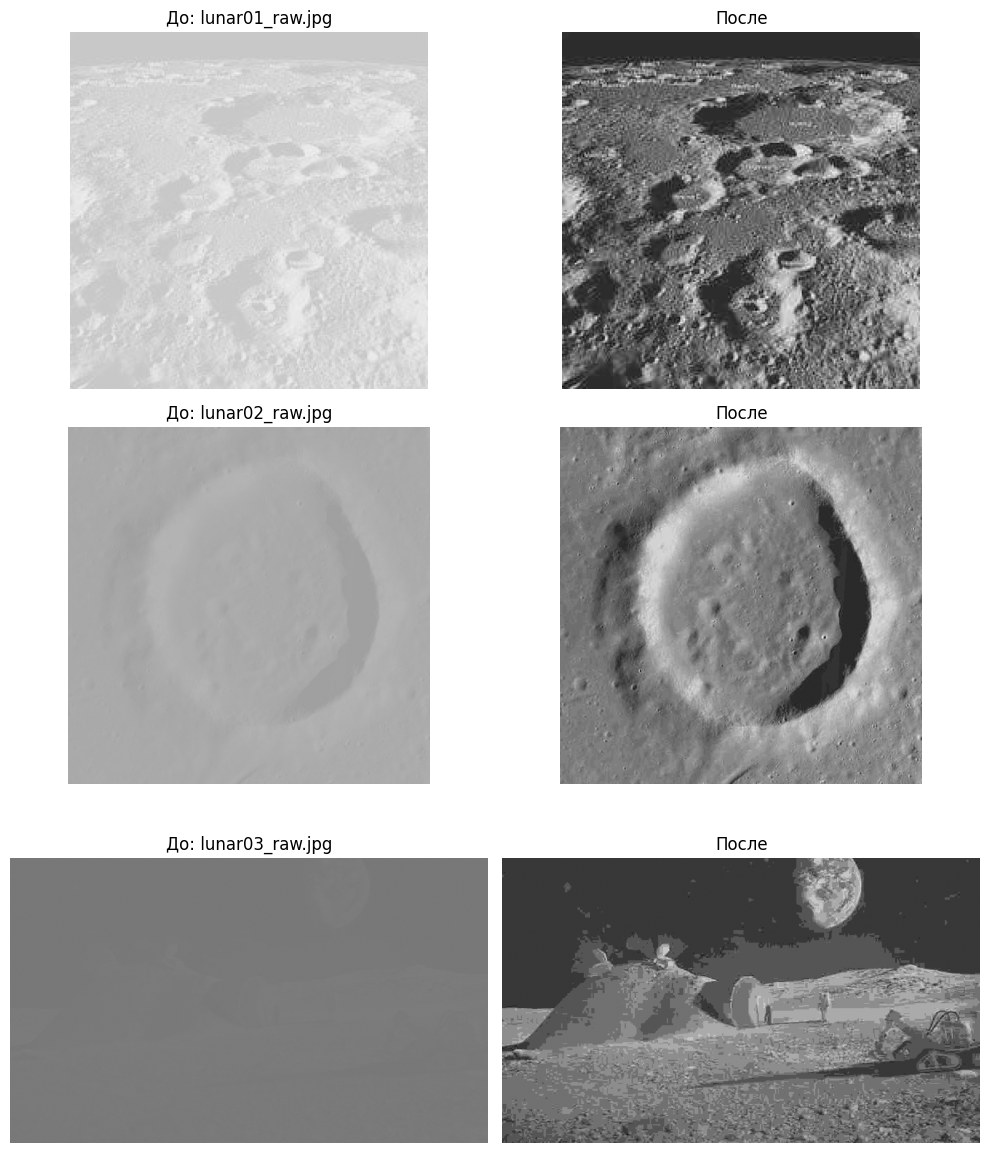

In [3]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

files = ["lunar01_raw.jpg", "lunar02_raw.jpg", "lunar03_raw.jpg"]

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for i, f in enumerate(files):
    raw = np.array(Image.open(f))
    mn, mx = raw.min(), raw.max()
    enh = np.clip((raw.astype(np.float32) - mn) / (mx - mn) * 255, 0, 255).astype(np.uint8)

    axes[i][0].imshow(raw, cmap="gray", vmin=0, vmax=255)
    axes[i][0].set_title(f"До: {f}")
    axes[i][0].axis("off")

    axes[i][1].imshow(enh, cmap="gray", vmin=0, vmax=255)
    axes[i][1].set_title("После")
    axes[i][1].axis("off")

plt.tight_layout()
plt.show()

Эпизод 2

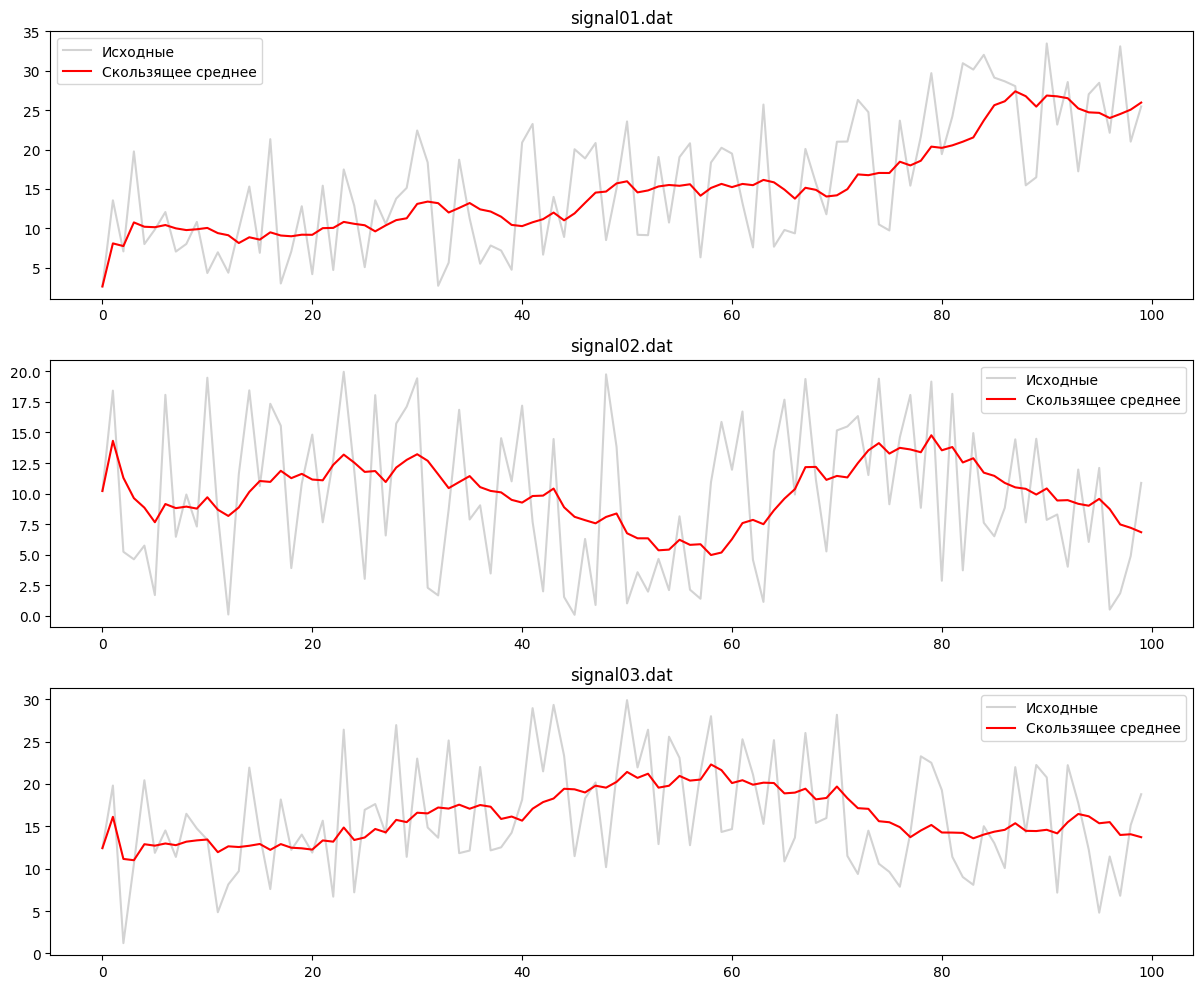

In [4]:
import numpy as np
import matplotlib.pyplot as plt

files = ["signal01.dat", "signal02.dat", "signal03.dat"]
window = 10

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for ax, f in zip(axes, files):
    data = np.loadtxt(f)
    filtered = np.array([data[max(0, i - window + 1):i + 1].mean() for i in range(len(data))])

    ax.plot(data, color="lightgray", label="Исходные")
    ax.plot(filtered, color="red", label="Скользящее среднее")
    ax.set_title(f)
    ax.legend()

plt.tight_layout()
plt.show()

Эпизод 3

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

u = np.loadtxt("start.dat.txt")
N = len(u)

A = np.eye(N)
A[np.arange(N), (np.arange(N) - 1) % N] = -1

fig, ax = plt.subplots(figsize=(6, 4))
ax.set_ylim(-0.5, 10.5)
ax.set_xlim(0, N - 1)
ax.grid(True)

line, = ax.plot([], [])
title = ax.set_title("")

def init():
    line.set_data([], [])
    return line, title

def update(frame):
    global u
    line.set_data(np.arange(N), u)
    title.set_text(f"Шаг {frame}")
    u = A @ u 
    return line, title

anim = FuncAnimation(fig, update, frames=256, init_func=init, interval=50, blit=False)

plt.close(fig) 

HTML(anim.to_jshtml())